In [27]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
%load_ext autoreload
%autoreload 2

import numpy as np
import time
from src.experiments import (stat_vs_params, calculate_variance)
from src.functions import (calculate_barlet_values, get_sin_signal, get_impulse_signal, calculate_stiring_matrix, calculate_complex_stiring_matrix, calculate_full_barlet_values,
                           calculate_spectrum_energy, calculate_spectrum_SNR, calculate_noise_level,get_noise, get_avp_signals, calculate_energy, calculate_fft)

from src.configs.config import init_rng, restart_rng
import src.configs.config as cfg
import src.configs.comon as comon
from src.plotting import plot_variance_vs_param, plot_mean_vs_param, create_config_table
import os
origin_config = init_rng()

path = "attachment/images/report"
os.makedirs(path,exist_ok=True)






The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


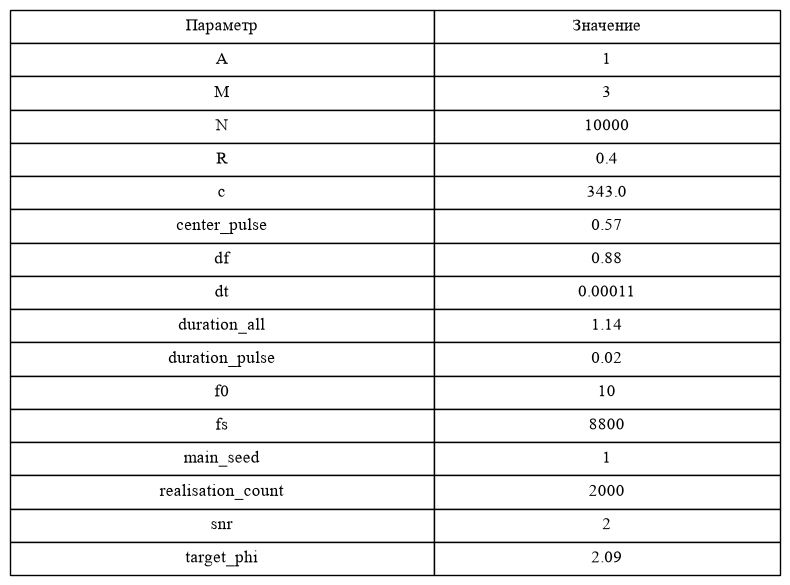

In [28]:
full_snr = 2
freq_range = np.arange(0.1,100,0.1)
origin_config["snr"] = full_snr
create_config_table(origin_config)

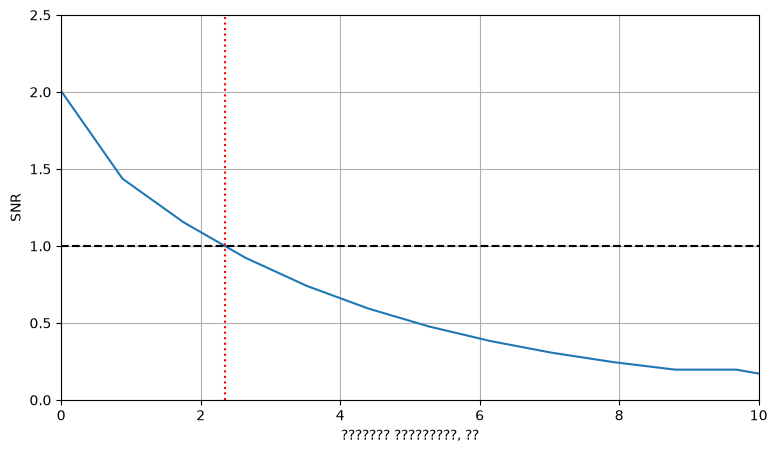

???????? SNR: 2.01
??????? ??? SNR = 1: 2.35 ??


In [29]:
from matplotlib import pyplot as plt

pulse_signal = get_impulse_signal(origin_config)
energy_signal = calculate_energy(pulse_signal, origin_config["time_vector"])
noise = get_noise(origin_config, np.random.default_rng(origin_config["main_seed"]), energy_signal)

spectrum_signal = calculate_fft(pulse_signal)
spectrum_noise = calculate_fft(noise)
freq_vector = origin_config["freq_vector"]
freq_values = np.arange(0, freq_range[-1], origin_config["df"])
snr_values = np.array([
    calculate_spectrum_SNR(spectrum_signal, spectrum_noise, freq_vector, f)
    for f in freq_values
])

i = np.where(snr_values < 1)[0][0]
f_at_one = np.interp(1, snr_values[i-1:i+1][::-1], freq_values[i-1:i+1][::-1])

plt.figure(figsize=(9, 5))
plt.plot(freq_values, snr_values)
plt.axhline(1, color="black", linestyle="--")
plt.axvline(f_at_one, color="red", linestyle=":")
plt.xlim(0, 10)
plt.ylim(0, 2.5)
plt.xlabel("??????? ?????????, ??")
plt.ylabel("SNR")
plt.grid()
plt.show()

print(f"???????? SNR: {snr_values[0]:.2f}")
print(f"??????? ??? SNR = 1: {f_at_one:.2f} ??")
